In [1]:
# ==============================================================================
# CELDA 1: CONFIGURACIÓN E IMPORTACIONES
# ==============================================================================
# 1. Instalar dependencias faltantes
!pip install mne -q

import os
import re
import joblib
import numpy as np
import pandas as pd
import mne
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.models import load_model, Model
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from IPython.display import display

# 2. Conectar Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3. Rutas base (Ajusta si es necesario)
BASE_TELEMETRY = Path("/content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry")
BASE_CASSETTE  = Path("/content/drive/MyDrive/Bimestre 7/Proyectos/sleep-cassette")

# 4. Constantes del proyecto
ETAPAS_VALIDAS = ["W", "N1", "N2", "N3", "REM"]
SEQ_LEN = 15
BATCH_SIZE = 128

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.
Mounted at /content/drive


In [2]:
# ==============================================================================
# CELDA 2 (CORREGIDA): PREPROCESAMIENTO CON RECORTE CLÍNICO DE VIGILIA
# ==============================================================================
def categorical_focal_loss(gamma=1.5):
    def loss(y_true, y_pred):
        y_pred = tf.cast(y_pred, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        return -tf.reduce_sum(y_true * tf.math.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred), axis=-1)
    return loss

CANALES_ESPERADOS = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal", "EMG submental"]
RE_SC = re.compile(r"^SC4(\d{2})(\d)[A-Za-z0-9]*-PSG\.edf$", re.IGNORECASE)
MAPA_ETAPAS = {"Sleep stage W": "W", "Sleep stage 1": "N1", "Sleep stage 2": "N2", "Sleep stage 3": "N3", "Sleep stage 4": "N3", "Sleep stage R": "REM"}

def descubrir_registros_cassette(base=BASE_CASSETTE):
    base = Path(base)
    registros = []
    for psg in sorted(base.glob("*-PSG.edf")):
        m = RE_SC.match(psg.name)
        if m is None: continue
        ss, noche = m.group(1), m.group(2)
        candidatos = sorted(base.glob(f"SC4{ss}{noche}*-Hypnogram.edf"))
        if not candidatos: continue
        registros.append({
            "psg": psg, "hyp": candidatos[0], "registro_id": f"SC4{ss}{noche}",
            "sujeto_id": f"SC_S{ss}", "cohorte": "Cassette", "noche": int(noche)
        })
    return registros

# ⚠️ FUNCIÓN RECUPERADA PARA EVITAR INFLAR EL ACCURACY
def indices_recorte(y, minutos=30, epoca_seg=30.0):
    if minutos is None: return 0, len(y)
    n_margen = int(minutos * 60 / epoca_seg)
    es_sueno = np.array([e in ("N1", "N2", "N3", "REM") for e in y])
    if not es_sueno.any(): return 0, len(y)
    primero = int(np.argmax(es_sueno))
    ultimo = len(y) - 1 - int(np.argmax(es_sueno[::-1]))
    return max(0, primero - n_margen), min(len(y), ultimo + 1 + n_margen)

def procesar_registro_cnn(reg):
    raw = mne.io.read_raw_edf(reg["psg"], preload=True, verbose="ERROR")
    fs = raw.info["sfreq"]
    raw.pick([c for c in CANALES_ESPERADOS if c in raw.ch_names])
    raw.filter(l_freq=0.3, h_freq=35.0, verbose=False)

    datos = np.vstack([raw.get_data()[raw.ch_names.index(c), :] * 1e6 if c in raw.ch_names else np.zeros(raw.n_times) for c in CANALES_ESPERADOS])
    ann = mne.read_annotations(reg["hyp"])

    muestras_epoca = int(round(30.0 * fs))
    n_epocas = datos.shape[1] // muestras_epoca
    epocas_data = np.transpose(datos[:, :n_epocas * muestras_epoca].reshape(4, n_epocas, muestras_epoca), (1, 0, 2))

    y = np.full(n_epocas, None, dtype=object)
    for onset, dur, desc in zip(ann.onset, ann.duration, ann.description):
        etapa = MAPA_ETAPAS.get(str(desc).strip())
        if etapa:
            i_ini, i_fin = max(0, int(np.floor(onset / 30.0))), min(n_epocas, int(np.ceil((onset + dur) / 30.0)))
            y[i_ini:i_fin] = etapa

    # ⚠️ APLICAMOS EL RECORTE ANTES DE FILTRAR
    i0, i1 = indices_recorte(y)
    epocas_data = epocas_data[i0:i1]
    y = y[i0:i1]

    valido = np.array([e in ETAPAS_VALIDAS for e in y])
    epocas_data, y = epocas_data[valido], y[valido]

    media = np.mean(epocas_data, axis=2, keepdims=True)
    desviacion = np.std(epocas_data, axis=2, keepdims=True) + 1e-8
    X_cnn = np.transpose((epocas_data - media) / desviacion, (0, 2, 1)).astype(np.float32)
    y_cnn = tf.keras.utils.to_categorical([{s: i for i, s in enumerate(ETAPAS_VALIDAS)}[s] for s in y], num_classes=5).astype(np.float32)

    meta = pd.DataFrame({"sujeto_id": reg["sujeto_id"], "registro_id": reg["registro_id"]}, index=range(len(y)))
    return X_cnn, y_cnn, meta

class MultimodalDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, indices, X_flat, y_flat, registro_ids, seq_len=15, batch_size=128, shuffle=False):
        self.indices = np.array(indices)
        self.X_flat, self.y_flat, self.registro_ids = X_flat, y_flat, registro_ids
        self.seq_len, self.pad, self.batch_size, self.shuffle = seq_len, seq_len // 2, batch_size, shuffle
        self.n_total = len(X_flat)

    def __len__(self): return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, idx):
        lote_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        X_batch = np.empty((len(lote_idx), self.seq_len, 3000, 4), dtype=np.float32)
        for i, center_idx in enumerate(lote_idx):
            reg_actual = self.registro_ids[center_idx]
            for w in range(self.seq_len):
                t_idx = center_idx - self.pad + w
                if t_idx < 0 or t_idx >= self.n_total or self.registro_ids[t_idx] != reg_actual:
                    X_batch[i, w] = self.X_flat[center_idx]
                else: X_batch[i, w] = self.X_flat[t_idx]
        return {'seq_eeg': X_batch[:, :, :, 0:2], 'seq_eog': X_batch[:, :, :, 2:3], 'seq_emg': X_batch[:, :, :, 3:4]}, self.y_flat[lote_idx]

In [3]:
# ==============================================================================
# CELDA 3: CONSTRUCCIÓN DEL DATASET HOLD-OUT (CERO DATA LEAKAGE)
# ==============================================================================
print("⏳ 1. Descubriendo registros en disco...")
registros_cas = descubrir_registros_cassette(BASE_CASSETTE)

# Sujetos usados en entrenamiento (primeras 40 noches)
sujetos_train_cas = {r["sujeto_id"] for r in registros_cas[:40]}

# Filtrar Hold-Out excluyendo cualquier sujeto de entrenamiento (elimina SC_S20)
# y tomar 20 noches estrictamente disjuntas por sujeto
registros_holdout_cas = [
    r for r in registros_cas[40:] if r["sujeto_id"] not in sujetos_train_cas
][:20]

sujetos_ho_cas = {r["sujeto_id"] for r in registros_holdout_cas}
assert len(sujetos_train_cas & sujetos_ho_cas) == 0, "¡Error: fuga de sujetos detectada!"

print(f"🔒 Hold-Out limpio: {len(registros_holdout_cas)} noches | {len(sujetos_ho_cas)} sujetos únicos (0% fuga)")
print(f"⏳ 2. Procesando {len(registros_holdout_cas)} noches de Hold-Out. Esto tomará un par de minutos...")

Xs, ys, ms = [], [], []
for reg in registros_holdout_cas:
    X, y, m = procesar_registro_cnn(reg)
    Xs.append(X); ys.append(y); ms.append(m)

X_test_holdout = np.concatenate(Xs, axis=0)
y_test_holdout = np.concatenate(ys, axis=0)
meta_test_holdout = pd.concat(ms, ignore_index=True)

y_true_holdout = np.argmax(y_test_holdout, axis=1)
reg_ids_test = meta_test_holdout["registro_id"].to_numpy()
indices_test = np.arange(len(X_test_holdout))

ds_test_holdout = MultimodalDataGenerator(
    indices_test, X_test_holdout, y_test_holdout, reg_ids_test, seq_len=SEQ_LEN, batch_size=BATCH_SIZE, shuffle=False
)
print(f"✅ Bóveda Hold-Out lista en RAM: {X_test_holdout.shape[0]} épocas generadas.")

⏳ 1. Descubriendo registros en disco...
🔒 Hold-Out limpio: 20 noches | 10 sujetos únicos (0% fuga)
⏳ 2. Procesando 20 noches de Hold-Out. Esto tomará un par de minutos...
✅ Bóveda Hold-Out lista en RAM: 24101 épocas generadas.


🚀 EVALUANDO VERSIÓN 4: EL IMPACTO DEL DOMAIN SHIFT

Cargando CRNN V4 (modelo_crnn_produccion.keras)...

-> 1. Procesando V4 CRNN PURA (TELEMETRY)...
Métricas CRNN Pura -> Acc: 0.6724 | F1: 0.6158 | Kappa: 0.5728

              precision    recall  f1-score   support

           W       0.83      0.91      0.87      7393
          N1       0.30      0.41      0.35      2492
          N2       0.85      0.52      0.64      9064
          N3       0.34      0.86      0.48      1600
         REM       0.82      0.68      0.74      3552

    accuracy                           0.67     24101
   macro avg       0.63      0.67      0.62     24101
weighted avg       0.75      0.67      0.68     24101


-> Extrayendo Embeddings 64D para los modelos tabulares V4...

-> 2. Procesando V4 + LGBM (SOLO TELEMETRY)...
Métricas LGBM (Telemetry) -> Acc: 0.6961 | F1: 0.6401 | Kappa: 0.5969

              precision    recall  f1-score   support

           W       0.93      0.78      0.85      7393
       

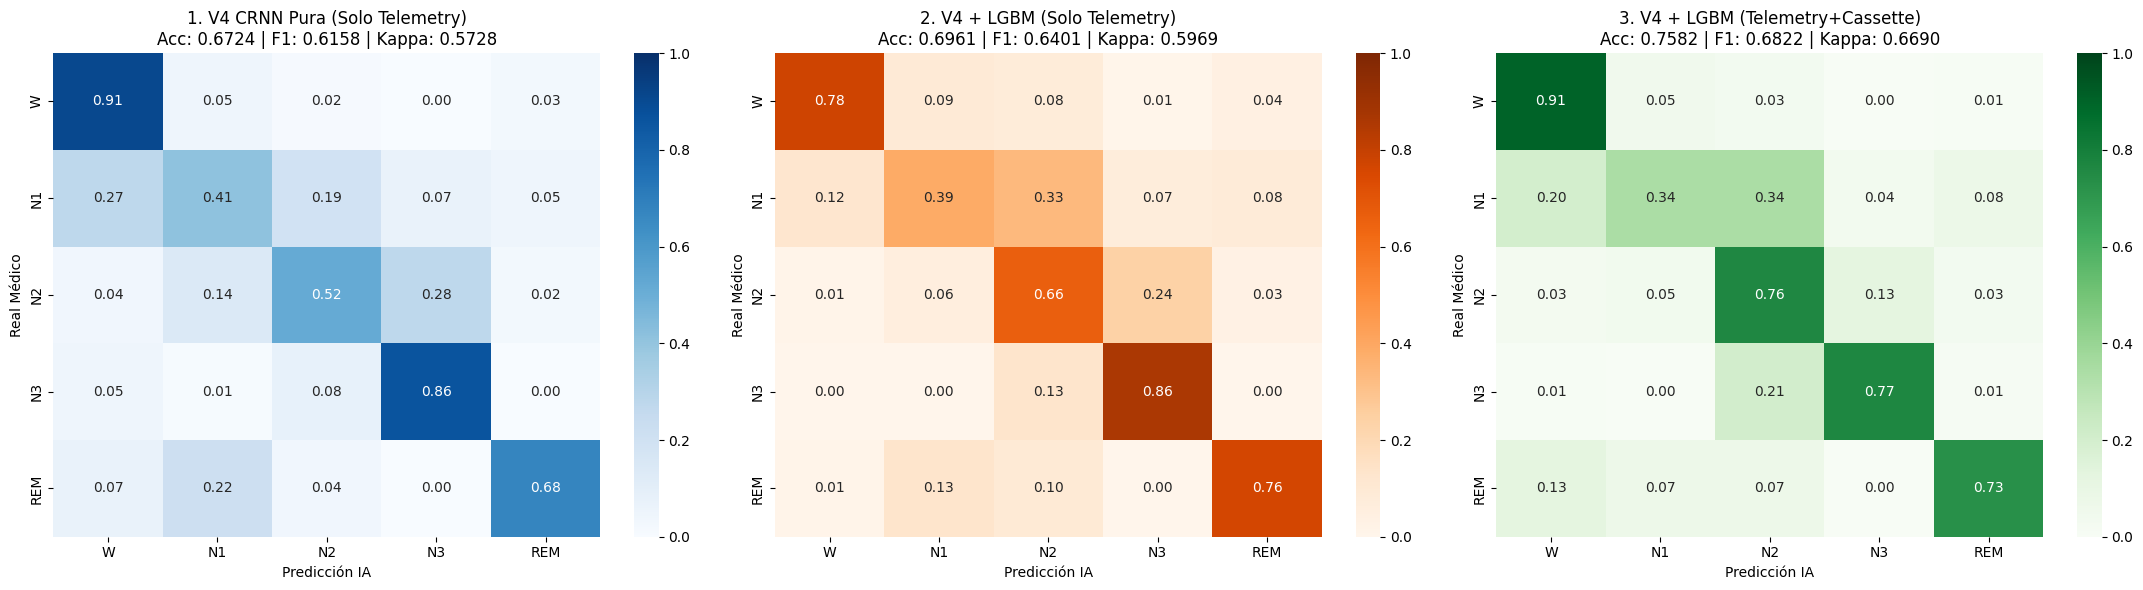

In [4]:
# ==============================================================================
# CELDA 4: EVALUACIÓN Y MATRICES (MODELOS 1 AL 3 - VERSIÓN 4)
# ==============================================================================
import numpy as np
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model, Model
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore') # Ocultar advertencias de LightGBM

print("="*80)
print("🚀 EVALUANDO VERSIÓN 4: EL IMPACTO DEL DOMAIN SHIFT")
print("="*80)

# 1. Cargar CRNN V4 (Telemetry Pura)
print("\nCargando CRNN V4 (modelo_crnn_produccion.keras)...")
crnn_v4 = load_model(
    BASE_TELEMETRY / "modelo_crnn_produccion.keras",
    custom_objects={'loss': categorical_focal_loss(gamma=2.0)} # Usaste gamma 2.0 en tu V4 original
)

# ------------------------------------------------------------------------------
# MODELO 1: V4 CRNN PURA (TELEMETRY)
# ------------------------------------------------------------------------------
print("\n-> 1. Procesando V4 CRNN PURA (TELEMETRY)...")
proba_v4_crnn = crnn_v4.predict(ds_test_holdout, verbose=0)
y_pred_1 = np.argmax(proba_v4_crnn, axis=1)

acc_1 = accuracy_score(y_true_holdout, y_pred_1)
f1_1 = f1_score(y_true_holdout, y_pred_1, average='macro')
kappa_1 = cohen_kappa_score(y_true_holdout, y_pred_1)
print(f"Métricas CRNN Pura -> Acc: {acc_1:.4f} | F1: {f1_1:.4f} | Kappa: {kappa_1:.4f}\n")
print(classification_report(y_true_holdout, y_pred_1, target_names=ETAPAS_VALIDAS))

# ------------------------------------------------------------------------------
# EXTRACCIÓN DE ESPACIO LATENTE 64D
# ------------------------------------------------------------------------------
print("\n-> Extrayendo Embeddings 64D para los modelos tabulares V4...")
# La capa de embeddings es la penúltima (antes de Softmax)
capa_salida_v4 = crnn_v4.layers[-2].output
extractor_v4 = Model(inputs=crnn_v4.inputs, outputs=capa_salida_v4)
X_64d_v4 = np.asarray(extractor_v4.predict(ds_test_holdout, verbose=0), dtype=np.float32)

# ------------------------------------------------------------------------------
# MODELO 2: V4 LGBM (TELEMETRY)
# ------------------------------------------------------------------------------
print("\n-> 2. Procesando V4 + LGBM (SOLO TELEMETRY)...")
lgbm_v4_tel = joblib.load(BASE_TELEMETRY / "motor_lightgbm_produccion.pkl")
y_pred_2 = lgbm_v4_tel.predict(X_64d_v4)

acc_2 = accuracy_score(y_true_holdout, y_pred_2)
f1_2 = f1_score(y_true_holdout, y_pred_2, average='macro')
kappa_2 = cohen_kappa_score(y_true_holdout, y_pred_2)
print(f"Métricas LGBM (Telemetry) -> Acc: {acc_2:.4f} | F1: {f1_2:.4f} | Kappa: {kappa_2:.4f}\n")
print(classification_report(y_true_holdout, y_pred_2, target_names=ETAPAS_VALIDAS))

# ------------------------------------------------------------------------------
# MODELO 3: V4 LGBM (TELEMETRY + CASSETTE)
# ------------------------------------------------------------------------------
print("\n-> 3. Procesando V4 + LGBM (TELEMETRY + CASSETTE)...")
lgbm_v4_univ = joblib.load(BASE_TELEMETRY / "motor_lightgbm_universal.pkl")
y_pred_3 = lgbm_v4_univ.predict(X_64d_v4)

acc_3 = accuracy_score(y_true_holdout, y_pred_3)
f1_3 = f1_score(y_true_holdout, y_pred_3, average='macro')
kappa_3 = cohen_kappa_score(y_true_holdout, y_pred_3)
print(f"Métricas LGBM (Universal) -> Acc: {acc_3:.4f} | F1: {f1_3:.4f} | Kappa: {kappa_3:.4f}\n")
print(classification_report(y_true_holdout, y_pred_3, target_names=ETAPAS_VALIDAS))

# ------------------------------------------------------------------------------
# GRÁFICOS: MATRICES DE CONFUSIÓN Y MÉTRICAS
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

cm_1 = confusion_matrix(y_true_holdout, y_pred_1, normalize='true')
sns.heatmap(cm_1, annot=True, fmt=".2f", cmap="Blues", ax=axes[0], xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
axes[0].set_title(f"1. V4 CRNN Pura (Solo Telemetry)\nAcc: {acc_1:.4f} | F1: {f1_1:.4f} | Kappa: {kappa_1:.4f}")
axes[0].set_ylabel("Real Médico"); axes[0].set_xlabel("Predicción IA")

cm_2 = confusion_matrix(y_true_holdout, y_pred_2, normalize='true')
sns.heatmap(cm_2, annot=True, fmt=".2f", cmap="Oranges", ax=axes[1], xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
axes[1].set_title(f"2. V4 + LGBM (Solo Telemetry)\nAcc: {acc_2:.4f} | F1: {f1_2:.4f} | Kappa: {kappa_2:.4f}")
axes[1].set_ylabel("Real Médico"); axes[1].set_xlabel("Predicción IA")

cm_3 = confusion_matrix(y_true_holdout, y_pred_3, normalize='true')
sns.heatmap(cm_3, annot=True, fmt=".2f", cmap="Greens", ax=axes[2], xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1)
axes[2].set_title(f"3. V4 + LGBM (Telemetry+Cassette)\nAcc: {acc_3:.4f} | F1: {f1_3:.4f} | Kappa: {kappa_3:.4f}")
axes[2].set_ylabel("Real Médico"); axes[2].set_xlabel("Predicción IA")

plt.tight_layout()
plt.show()

# Liberar memoria de la GPU
del crnn_v4, extractor_v4, lgbm_v4_tel, lgbm_v4_univ
tf.keras.backend.clear_session()

In [5]:
# ==============================================================================
# CELDA 5: EXTRACCIÓN DE HIPERPARÁMETROS DE LOS ENSAMBLES LIGHTGBM (V4 Y V5)
# ==============================================================================
import pandas as pd
import joblib

print("📊 Extrayendo hiperparámetros de los motores LightGBM históricos...")

# Diccionario con las rutas de los modelos tabulares
rutas_lgbm = {
    '2. V4 + LGBM (Solo Telemetry)': BASE_TELEMETRY / "motor_lightgbm_produccion.pkl",
    '3. V4 + LGBM (Telemetry+Cassette)': BASE_TELEMETRY / "motor_lightgbm_universal.pkl",
    '5. V5 Base + LGBM Optuna': BASE_TELEMETRY / "motor_lightgbm_universal_optuna_v7.pkl",
    '7. V5 Óptima + LGBM Optuna': BASE_TELEMETRY / "motor_lightgbm_optimo_v7.pkl"
}

# Los hiperparámetros clave que evaluará el jurado en tu tesis
parametros_clave = [
    'n_estimators', 'learning_rate', 'max_depth', 'num_leaves',
    'min_child_samples', 'subsample', 'colsample_bytree', 'reg_alpha', 'reg_lambda'
]

datos_params = {'Hiperparámetro': parametros_clave}

for nombre, ruta in rutas_lgbm.items():
    if ruta.exists():
        clf = joblib.load(ruta)
        params = clf.get_params()
        # Extraer cada parámetro, si no existe o es None, ponemos un formato estándar
        datos_params[nombre] = [params.get(p, 'N/A') for p in parametros_clave]
        print(f"✅ Cargado con éxito: {nombre}")
    else:
        print(f"⚠️ Archivo no encontrado: {ruta.name}")
        datos_params[nombre] = ['No disponible'] * len(parametros_clave)

# Construir el DataFrame para visualización
df_hiperparametros = pd.DataFrame(datos_params)

print("\n" + "="*95)
print("📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)")
print("="*95)
display(df_hiperparametros)

📊 Extrayendo hiperparámetros de los motores LightGBM históricos...
✅ Cargado con éxito: 2. V4 + LGBM (Solo Telemetry)
✅ Cargado con éxito: 3. V4 + LGBM (Telemetry+Cassette)
✅ Cargado con éxito: 5. V5 Base + LGBM Optuna
✅ Cargado con éxito: 7. V5 Óptima + LGBM Optuna

📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)


,Hiperparámetro,2. V4 + LGBM (Solo Telemetry),3. V4 + LGBM (Telemetry+Cassette),5. V5 Base + LGBM Optuna,7. V5 Óptima + LGBM Optuna
0,n_estimators,300.00,500.00,550.000000,500.000000
1,learning_rate,0.05,0.05,0.076540,0.077097
2,max_depth,-1.00,-1.00,7.000000,7.000000
3,num_leaves,31.00,63.00,50.000000,55.000000
4,min_child_samples,20.00,20.00,240.000000,120.000000
5,subsample,1.00,1.00,0.752904,0.913735
6,colsample_bytree,1.00,1.00,0.673634,0.553946
7,reg_alpha,0.00,0.00,0.078168,0.021568
8,reg_lambda,0.00,0.00,0.190848,0.492141


In [6]:
# ==============================================================================
# CELDA 5B (CORREGIDA): EXTRACCIÓN DE HIPERPARÁMETROS ARQUITECTÓNICOS Y GAMMA
# ==============================================================================
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import load_model

print("🧠 Inspeccionando grafos neuronales para extraer hiperparámetros de la CRNN...")

rutas_crnn = {
    '1. V4 CRNN Pura (Telemetry)': BASE_TELEMETRY / "modelo_crnn_produccion.keras",
    '4. V5 Base (CRNN Telemetry+Cassette)': BASE_TELEMETRY / "modelo_crnn_universal_v7.keras",
    '6. V5 Óptima (CRNN)': BASE_TELEMETRY / "modelo_crnn_maestro_optimo_v7.keras"
}

datos_crnn = {}

for nombre, ruta in rutas_crnn.items():
    if ruta.exists():
        print(f"  -> Analizando: {nombre}...")

        # ⚠️ DEFINIR EL GAMMA SEGÚN EL MODELO EVALUADO
        # V5 Óptima usa 1.5 por el ajuste fino; las versiones base usan 2.0 por defecto.
        gamma_valor = 1.5 if "Óptima" in nombre else 2.0

        # Cargamos el modelo pasándole el gamma correspondiente para evitar errores
        modelo = load_model(ruta, custom_objects={'loss': categorical_focal_loss(gamma=gamma_valor)})

        params_red = {}
        params_red['Total_Params'] = f"{modelo.count_params():,}"

        # Asignar explícitamente el valor de Gamma extraído del contexto del modelo
        params_red['Focal_Loss_Gamma'] = gamma_valor

        try:
            params_red['Learning_Rate'] = float(modelo.optimizer.learning_rate.numpy())
        except:
            params_red['Learning_Rate'] = "N/A"

        bilstm_units = "N/A"
        dropouts = []
        spatial = []
        noise = []

        # Búsqueda segura capa por capa (incluyendo TimeDistributed)
        for layer in modelo.layers:
            # Extraer capa interna si está envuelta en TimeDistributed
            inner_layer = layer.layer if hasattr(layer, 'layer') else layer
            layer_class = inner_layer.__class__.__name__.lower()

            # 1. Unidades BiLSTM
            if 'bidirectional' in layer.name.lower() or 'lstm' in layer_class:
                if hasattr(layer, 'layer'):
                    bilstm_units = layer.layer.units
                elif hasattr(layer, 'units'):
                    bilstm_units = layer.units

            # 2. Dropouts (asegurando que tengan el atributo rate)
            if hasattr(inner_layer, 'rate'):
                if 'spatial' in layer_class or 'spatialdropout' in layer_class:
                    spatial.append(inner_layer.rate)
                elif 'dropout' in layer_class:
                    dropouts.append(inner_layer.rate)

            # 3. Gaussian Noise (asegurando que tengan el atributo stddev)
            if hasattr(inner_layer, 'stddev'):
                noise.append(inner_layer.stddev)

        params_red['BiLSTM_Units'] = bilstm_units

        # Dimensión Latente (Penúltima capa antes de Softmax)
        try:
            params_red['Latent_Dim'] = modelo.layers[-2].units
        except:
            params_red['Latent_Dim'] = "N/A"

        params_red['Max_Dropout'] = max(dropouts) if dropouts else "0.0"
        params_red['Spatial_Dropout'] = max(spatial) if spatial else "No aplicado"
        params_red['Gaussian_Noise (Std)'] = noise[0] if noise else "No aplicado"

        datos_crnn[nombre] = params_red

        # Limpiar memoria
        del modelo
        tf.keras.backend.clear_session()
    else:
        print(f"  ⚠️ Archivo no encontrado: {ruta.name}")

# Construir el DataFrame
df_audit_crnn = pd.DataFrame(datos_crnn)

print("\n" + "="*85)
print("📋 TABLA 2: ARQUITECTURA E HIPERPARÁMETROS DE EXTRACCIÓN (REDES NEURONALES CRNN)")
print("="*85)
display(df_audit_crnn)

🧠 Inspeccionando grafos neuronales para extraer hiperparámetros de la CRNN...
  -> Analizando: 1. V4 CRNN Pura (Telemetry)...
  -> Analizando: 4. V5 Base (CRNN Telemetry+Cassette)...
  -> Analizando: 6. V5 Óptima (CRNN)...

📋 TABLA 2: ARQUITECTURA E HIPERPARÁMETROS DE EXTRACCIÓN (REDES NEURONALES CRNN)


,1. V4 CRNN Pura (Telemetry),4. V5 Base (CRNN Telemetry+Cassette),6. V5 Óptima (CRNN)
Total_Params,"246,053","246,053","246,053"
Focal_Loss_Gamma,2.0,2.0,1.5
Learning_Rate,0.000125,0.000125,0.000125
BiLSTM_Units,N/A,N/A,N/A
Latent_Dim,64,64,64
Max_Dropout,0.4,0.4,0.4
Spatial_Dropout,No aplicado,0.2,0.2
Gaussian_Noise (Std),No aplicado,0.15,0.15


In [7]:
import joblib
import pandas as pd

# 1. Definir la ruta del nuevo modelo LightGBM Contextual (192D)
ruta_lgbm_contextual = BASE_TELEMETRY / "motor_lightgbm_contextual_192d_v7.pkl"

# 2. Cargar el modelo si existe en disco
if ruta_lgbm_contextual.exists():
    print(f"📦 Cargando modelo desde: {ruta_lgbm_contextual.name}...")
    clf_loaded = joblib.load(ruta_lgbm_contextual)

    # 3. Extraer los hiperparámetros del clasificador LightGBM
    params_contextual = clf_loaded.get_params()

    # 4. Seleccionar los parámetros clave que componen tu Tabla 1
    hiperparametros_interes = [
        'n_estimators', 'learning_rate', 'max_depth', 'num_leaves',
        'min_child_samples', 'subsample', 'colsample_bytree',
        'reg_alpha', 'reg_lambda'
    ]

    # Crear un diccionario filtrado con los valores del nuevo modelo
    dict_nuevo_modelo = {hp: params_contextual.get(hp, "N/A") for hp in hiperparametros_interes}

    # 5. Si ya tienes tu DataFrame anterior (ej. df_hiperparametros), simplemente agregas la columna:
    # df_hiperparametros['8. V7 Ensamble Contextual (192D + Optuna)'] = pd.Series(dict_nuevo_modelo)

    # Ejemplo directo creando la tabla completa o actualizándola:
    print("\n" + "="*80)
    print("📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)")
    print("="*80)

    # Si deseas ver únicamente este nuevo modelo en formato limpio:
    df_nuevo = pd.DataFrame(list(dict_nuevo_modelo.items()), columns=['Hiperparámetro', 'V7 Ensamble Contextual (192D)'])
    display(df_nuevo)

else:
    print(f"⚠️ No se encontró el archivo en: {ruta_lgbm_contextual}")

📦 Cargando modelo desde: motor_lightgbm_contextual_192d_v7.pkl...

📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)


,Hiperparámetro,V7 Ensamble Contextual (192D)
0,n_estimators,600.000000
1,learning_rate,0.064440
2,max_depth,7.000000
3,num_leaves,62.000000
4,min_child_samples,130.000000
5,subsample,0.743569
6,colsample_bytree,0.583576
7,reg_alpha,0.376046
8,reg_lambda,1.464700


In [8]:
import pandas as pd
import joblib

# 1. Recuperamos (o definimos) los datos de las versiones anteriores que ya tenías
data_evolucion = {
    'Hiperparámetro': [
        'Contexto_Latente (Dim)', 'n_estimators', 'learning_rate', 'max_depth',
        'num_leaves', 'min_child_samples', 'subsample', 'colsample_bytree',
        'reg_alpha', 'reg_lambda'
    ],
    '2. V4 + LGBM (Solo Telemetry)': [64, 300.0, 0.05, -1.0, 31.0, 20.0, 1.0, 1.0, 0.0, 0.0],
    '3. V4 + LGBM (Telemetry+Cassette)': [64, 500.0, 0.05, -1.0, 63.0, 20.0, 1.0, 1.0, 0.0, 0.0],
    '5. V5 Base + LGBM Optuna': [64, 550.0, 0.076540, 7.0, 50.0, 240.0, 0.752904, 0.673634, 0.078168, 0.190848],
    '7. V5 Óptima + LGBM Optuna': [64, 500.0, 0.077097, 7.0, 55.0, 120.0, 0.913735, 0.553946, 0.021568, 0.492141]
}

df_tabla1 = pd.DataFrame(data_evolucion)
df_tabla1.set_index('Hiperparámetro', inplace=True)

# 2. Cargamos el nuevo modelo LightGBM Contextual 192D para extraer sus parámetros automáticamente
ruta_lgbm_contextual = BASE_TELEMETRY / "motor_lightgbm_contextual_192d_v7.pkl"

if ruta_lgbm_contextual.exists():
    clf_contextual = joblib.load(ruta_lgbm_contextual)
    params_ctx = clf_contextual.get_params()

    # 3. Creamos la lista de valores incluyendo la dimensión del contexto (192D) al inicio
    columna_nueva = [192] + [
        params_ctx.get(hp, "N/A") for hp in [
            'n_estimators', 'learning_rate', 'max_depth', 'num_leaves',
            'min_child_samples', 'subsample', 'colsample_bytree',
            'reg_alpha', 'reg_lambda'
        ]
    ]

    # 4. Añadimos la columna al DataFrame unificado
    df_tabla1['8. V7 Ensamble Contextual (192D)'] = columna_nueva

# 5. Imprimimos el resultado con formato de título limpio
print("="*115)
print("📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)")
print("="*115)
display(df_tabla1)

📋 TABLA 1: EVOLUCIÓN DE HIPERPARÁMETROS EN CLASIFICADORES TABULARES (LIGHTGBM)


,2. V4 + LGBM (Solo Telemetry),3. V4 + LGBM (Telemetry+Cassette),5. V5 Base + LGBM Optuna,7. V5 Óptima + LGBM Optuna,8. V7 Ensamble Contextual (192D)
Hiperparámetro,,,,,
Contexto_Latente (Dim),64.00,64.00,64.000000,64.000000,192.000000
n_estimators,300.00,500.00,550.000000,500.000000,600.000000
learning_rate,0.05,0.05,0.076540,0.077097,0.064440
max_depth,-1.00,-1.00,7.000000,7.000000,7.000000
num_leaves,31.00,63.00,50.000000,55.000000,62.000000
min_child_samples,20.00,20.00,240.000000,120.000000,130.000000
subsample,1.00,1.00,0.752904,0.913735,0.743569
colsample_bytree,1.00,1.00,0.673634,0.553946,0.583576
reg_alpha,0.00,0.00,0.078168,0.021568,0.376046


In [12]:
# ==============================================================================
# CELDA A: ACUMULADOR DE MÉTRICAS Y FUNCIONES AUXILIARES (192D + HMM)
# ==============================================================================
resultados_global = []
resultados_estadios = []
predicciones_modelos = {}

def registrar_resultado(nombre_modelo, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    kap = cohen_kappa_score(y_true, y_pred)
    f1_clases = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2, 3, 4])

    resultados_global.append({
        "Modelo / Fase de Ablación": nombre_modelo,
        "Accuracy": round(acc, 4),
        "F1-Macro": round(f1m, 4),
        "Kappa": round(kap, 4),
    })
    resultados_estadios.append({
        "Versión del Sistema": nombre_modelo,
        "W": round(f1_clases[0], 2),
        "N1": round(f1_clases[1], 2),
        "N2": round(f1_clases[2], 2),
        "N3": round(f1_clases[3], 2),
        "REM": round(f1_clases[4], 2),
    })
    predicciones_modelos[nombre_modelo] = np.asarray(y_pred)
    print(f"✅ {nombre_modelo:42s} | Acc: {acc:.4f} | F1-M: {f1m:.4f} | Kappa: {kap:.4f} | F1-N1: {f1_clases[1]:.4f}")

def expandir_contexto_192d(X_64d, reg_ids):
    """Construye [E_{t-1}, E_t, E_{t+1}] respetando fronteras de cada noche."""
    n = len(X_64d)
    X_192 = np.empty((n, X_64d.shape[1] * 3), dtype=np.float32)
    for i in range(n):
        prev_i = i - 1 if (i > 0 and reg_ids[i - 1] == reg_ids[i]) else i
        next_i = i + 1 if (i < n - 1 and reg_ids[i + 1] == reg_ids[i]) else i
        X_192[i] = np.concatenate([X_64d[prev_i], X_64d[i], X_64d[next_i]])
    return X_192

def viterbi_por_noche(probas, reg_ids, A_trans):
    """Decodificación de Viterbi en espacio logarítmico por registro."""
    log_A = np.log(np.clip(A_trans, 1e-12, 1.0))
    log_P = np.log(np.clip(probas, 1e-12, 1.0))
    y_out = np.zeros(len(probas), dtype=int)

    for reg in np.unique(reg_ids):
        idx = np.where(reg_ids == reg)[0]
        T, K = len(idx), log_P.shape[1]
        dp = np.zeros((T, K))
        ptr = np.zeros((T, K), dtype=int)
        dp[0] = log_P[idx[0]]
        for t in range(1, T):
            scores = dp[t - 1][:, None] + log_A
            ptr[t] = np.argmax(scores, axis=0)
            dp[t] = np.max(scores, axis=0) + log_P[idx[t]]
        path = np.zeros(T, dtype=int)
        path[-1] = np.argmax(dp[-1])
        for t in range(T - 2, -1, -1):
            path[t] = ptr[t + 1, path[t + 1]]
        y_out[idx] = path
    return y_out

In [13]:
# ==============================================================================
# CELDA B: EVALUACIÓN UNIFICADA DE V4, V5 Y V6 SOBRE HOLD-OUT LIMPIO
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

# --- 1. FASE V4 ---
print("\n🚀 Evaluando Fase V4...")
crnn_v4 = load_model(BASE_TELEMETRY / "modelo_crnn_produccion.keras",
                     custom_objects={"loss": categorical_focal_loss(gamma=2.0)})
registrar_resultado("V4 (CRNN Pura - Baseline)", y_true_holdout,
                    np.argmax(crnn_v4.predict(ds_test_holdout, verbose=0), axis=1))

ext_v4 = Model(inputs=crnn_v4.inputs, outputs=crnn_v4.layers[-2].output)
X_64d_v4 = np.asarray(ext_v4.predict(ds_test_holdout, verbose=0), dtype=np.float32)

lgbm_v4_tel = joblib.load(BASE_TELEMETRY / "motor_lightgbm_produccion.pkl")
registrar_resultado("V4 (Ensamble LightGBM Simple)", y_true_holdout, lgbm_v4_tel.predict(X_64d_v4))

lgbm_v4_univ = joblib.load(BASE_TELEMETRY / "motor_lightgbm_universal.pkl")
registrar_resultado("V4 (LGBM Telemetry+Cassette)", y_true_holdout, lgbm_v4_univ.predict(X_64d_v4))

del crnn_v4, ext_v4, lgbm_v4_tel, lgbm_v4_univ
tf.keras.backend.clear_session()

# --- 2. FASE V5 BASE ---
print("\n🚀 Evaluando Fase V5 Base...")
crnn_v5b = load_model(BASE_TELEMETRY / "modelo_crnn_universal_v7.keras",
                      custom_objects={"loss": categorical_focal_loss(gamma=2.0)})
registrar_resultado("V5 Base (CRNN + Data Augmentation)", y_true_holdout,
                    np.argmax(crnn_v5b.predict(ds_test_holdout, verbose=0), axis=1))

ext_v5b = Model(inputs=crnn_v5b.inputs, outputs=crnn_v5b.layers[-2].output)
X_64d_v5b = np.asarray(ext_v5b.predict(ds_test_holdout, verbose=0), dtype=np.float32)

lgbm_v5b = joblib.load(BASE_TELEMETRY / "motor_lightgbm_universal_optuna_v7.pkl")
registrar_resultado("V5 Base (LightGBM)", y_true_holdout, lgbm_v5b.predict(X_64d_v5b))

del crnn_v5b, ext_v5b, lgbm_v5b
tf.keras.backend.clear_session()

# --- 3. FASE V5 ÓPTIMA + V6 (192D) ---
print("\n🚀 Evaluando Fase V5 Óptima y Fase V6...")
crnn_v5o = load_model(BASE_TELEMETRY / "modelo_crnn_maestro_optimo_v7.keras",
                      custom_objects={"loss": categorical_focal_loss(gamma=1.5)})
registrar_resultado("V5 Óptimo (CRNN + Data Augmentation)", y_true_holdout,
                    np.argmax(crnn_v5o.predict(ds_test_holdout, verbose=0), axis=1))

ext_v5o = Model(inputs=crnn_v5o.inputs, outputs=crnn_v5o.layers[-2].output)
X_64d_v5o = np.asarray(ext_v5o.predict(ds_test_holdout, verbose=0), dtype=np.float32)

lgbm_v5o = joblib.load(BASE_TELEMETRY / "motor_lightgbm_optimo_v7.pkl")
registrar_resultado("V5 Óptimo (LightGBM Optuna)", y_true_holdout, lgbm_v5o.predict(X_64d_v5o))

# Expansión 192D (V6 Fase B) — guardamos X_192d_v6 en RAM por si corres V7 aquí mismo
X_192d_v6 = expandir_contexto_192d(X_64d_v5o, reg_ids_test)
lgbm_v6 = joblib.load(BASE_TELEMETRY / "motor_lightgbm_contextual_192d_v7.pkl")
proba_v6 = lgbm_v6.predict_proba(X_192d_v6)
registrar_resultado("V6 Fase B (Contexto 192D)", y_true_holdout, np.argmax(proba_v6, axis=1))

# Si tienes guardada la matriz de transición HMM en Drive, descomenta estas 3 líneas:
# A_hmm = joblib.load(BASE_TELEMETRY / "hmm_produccion.pkl")
# y_v6_hmm = viterbi_por_noche(proba_v6, reg_ids_test, A_hmm)
# registrar_resultado("V6 Fase C (Suavizado HMM)", y_true_holdout, y_v6_hmm)

del crnn_v5o, ext_v5o, lgbm_v5o, lgbm_v6
tf.keras.backend.clear_session()


🚀 Evaluando Fase V4...
✅ V4 (CRNN Pura - Baseline)                  | Acc: 0.6724 | F1-M: 0.6158 | Kappa: 0.5728 | F1-N1: 0.3461
✅ V4 (Ensamble LightGBM Simple)              | Acc: 0.6961 | F1-M: 0.6401 | Kappa: 0.5969 | F1-N1: 0.3755
✅ V4 (LGBM Telemetry+Cassette)               | Acc: 0.7582 | F1-M: 0.6822 | Kappa: 0.6690 | F1-N1: 0.3862

🚀 Evaluando Fase V5 Base...
✅ V5 Base (CRNN + Data Augmentation)         | Acc: 0.7486 | F1-M: 0.6833 | Kappa: 0.6587 | F1-N1: 0.3928
✅ V5 Base (LightGBM)                         | Acc: 0.7737 | F1-M: 0.7093 | Kappa: 0.6869 | F1-N1: 0.4068

🚀 Evaluando Fase V5 Óptima y Fase V6...
✅ V5 Óptimo (CRNN + Data Augmentation)       | Acc: 0.7564 | F1-M: 0.6912 | Kappa: 0.6690 | F1-N1: 0.4067
✅ V5 Óptimo (LightGBM Optuna)                | Acc: 0.7818 | F1-M: 0.7137 | Kappa: 0.6984 | F1-N1: 0.4066
✅ V6 Fase B (Contexto 192D)                  | Acc: 0.7838 | F1-M: 0.7139 | Kappa: 0.7005 | F1-N1: 0.4082


In [14]:
# ==============================================================================
# CELDA B2: EVALUACIÓN DE V6 (HMM) Y V7 (EXP 3 Y EXP 4) SOBRE HOLD-OUT LIMPIO
# ==============================================================================
from scipy.fft import rfft
from scipy.ndimage import convolve1d

# 1. Cargar artefactos V7/V8 guardados en Drive
clf_lgbm_v8 = joblib.load(BASE_TELEMETRY / "motor_lightgbm_espectral_528d_v8.pkl")
hmm_data    = np.load(BASE_TELEMETRY / "hmm_transicion_v8.npz")
A_hmm_v8, pi_hmm_v8 = hmm_data["A"], hmm_data["pi"]

# Función Viterbi con probabilidades iniciales pi (igual a tu notebook)
def viterbi_con_pi(probas, reg_ids, A, pi):
    logA, logpi = np.log(A + 1e-12), np.log(pi + 1e-12)
    log_emision = np.log(probas + 1e-12)
    y_out = np.zeros(len(probas), dtype=int)

    for rid in np.unique(reg_ids):
        mask = (reg_ids == rid)
        le = log_emision[mask]
        n, K = le.shape
        delta = np.zeros((n, K), dtype=np.float64)
        psi = np.zeros((n, K), dtype=int)
        delta[0] = logpi + le[0]
        for t in range(1, n):
            m = delta[t - 1][:, None] + logA
            psi[t] = np.argmax(m, axis=0)
            delta[t] = m[psi[t], np.arange(K)] + le[t]
        camino = np.zeros(n, dtype=int)
        camino[-1] = int(np.argmax(delta[-1]))
        for t in range(n - 2, -1, -1):
            camino[t] = psi[t + 1, camino[t + 1]]
        y_out[mask] = camino
    return y_out

# --- A. V6 Fase C (Suavizado HMM usando proba_v6 de la Celda B) ---
if "proba_v6" in globals():
    y_v6_hmm = viterbi_con_pi(proba_v6, reg_ids_test, A_hmm_v8, pi_hmm_v8)
    registrar_resultado("V6 Fase C (Suavizado HMM)", y_true_holdout, y_v6_hmm)

# --- B. Extracción de rama espectral 336D (Bloques 5s + P10-P90 + Contexto 2m/7.5m) ---
print("\n⏳ Extrayendo características espectrales 336D (V7) sobre Hold-Out limpio...")
BANDAS = [(0.3, 4), (4, 8), (8, 12), (12, 16), (16, 30), (30, 35)]
FRECS_5S = np.fft.rfftfreq(500, 1.0 / 100.0)
VENTANA_HANN = np.hanning(500).astype(np.float32)[None, None, :, None]
MASCARAS_BANDAS = [(FRECS_5S >= a) & (FRECS_5S < b) for a, b in BANDAS]
TRIANGULAR_15 = np.r_[1:9, 7:0:-1].astype(np.float32)
TRIANGULAR_15 /= TRIANGULAR_15.sum()

def extraer_336d_por_noche(X_raw, reg_ids):
    n = len(X_raw)
    X_spec_5s = np.empty((n, 6, 24), dtype=np.float32)
    for i in range(0, n, 256):
        bloque = X_raw[i:i+256].reshape(-1, 6, 500, 4)
        potencia = (np.abs(rfft(bloque * VENTANA_HANN, axis=2)) ** 2) / 500.0
        X_spec_5s[i:i+len(bloque)] = np.concatenate(
            [np.log1p(potencia[:, :, mask].mean(axis=2)) for mask in MASCARAS_BANDAS],
            axis=-1
        )

    X_z_all      = np.empty((n, 6, 24), dtype=np.float32)
    X_centro_all = np.empty((n, 24), dtype=np.float32)
    X_pasado_all = np.empty((n, 24), dtype=np.float32)

    for rid in np.unique(reg_ids):
        mask = (reg_ids == rid)
        x = X_spec_5s[mask]
        n_noche = len(x)
        q10, mediana, q90 = np.percentile(x.reshape(-1, 24), [10, 50, 90], axis=0)
        z = np.clip((x - mediana) / np.maximum(q90 - q10, 0.05), -5.0, 5.0).astype(np.float32)

        media = z.mean(axis=1)
        centro = convolve1d(media, TRIANGULAR_15, axis=0, mode="nearest")
        pad_pasado = np.pad(media, ((3, 0), (0, 0)), mode="edge")
        pasado = sum(pad_pasado[k:k+n_noche] for k in range(4)) / 4.0

        X_z_all[mask]      = z
        X_centro_all[mask] = centro
        X_pasado_all[mask] = pasado

    return np.hstack((X_spec_5s.reshape(n, -1), X_z_all.reshape(n, -1), X_centro_all, X_pasado_all)).astype(np.float32)

X_336d_spec = extraer_336d_por_noche(X_test_holdout, reg_ids_test)
X_528d_ho   = np.hstack((X_192d_v6, X_336d_spec))

# --- C. V7 Exp 3 (528D + Pesos Agresivo_N1) ---
print("🚀 Evaluando Fase V7 (528D)...")
proba_v7_exp3 = clf_lgbm_v8.predict_proba(X_528d_ho)
y_pred_v7_exp3 = np.argmax(proba_v7_exp3, axis=1)
registrar_resultado("V7 Exp 3 (+ Pesos Agresivo_N1, 528D)", y_true_holdout, y_pred_v7_exp3)

# --- D. V7 Exp 4 (Exp 3 + Auditoría HMM) ---
y_pred_v7_exp4 = viterbi_con_pi(proba_v7_exp3, reg_ids_test, A_hmm_v8, pi_hmm_v8)
registrar_resultado("V7 Exp 4 (Exp 3 + Auditoría HMM)", y_true_holdout, y_pred_v7_exp4)

✅ V6 Fase C (Suavizado HMM)                  | Acc: 0.7874 | F1-M: 0.7138 | Kappa: 0.7045 | F1-N1: 0.3876

⏳ Extrayendo características espectrales 336D (V7) sobre Hold-Out limpio...
🚀 Evaluando Fase V7 (528D)...
✅ V7 Exp 3 (+ Pesos Agresivo_N1, 528D)       | Acc: 0.7971 | F1-M: 0.7286 | Kappa: 0.7188 | F1-N1: 0.4144
✅ V7 Exp 4 (Exp 3 + Auditoría HMM)           | Acc: 0.7993 | F1-M: 0.7260 | Kappa: 0.7211 | F1-N1: 0.3933


In [15]:
# ==============================================================================
# CELDA C: GENERACIÓN Y EXPORTACIÓN DE TABLAS POR SEPARADO
# ==============================================================================
CARPETA_SALIDA = BASE_TELEMETRY / "tablas_paper_limpias"
CARPETA_SALIDA.mkdir(exist_ok=True)

df_cuadro3_global = pd.DataFrame(resultados_global)
df_cuadro4_estadios = pd.DataFrame(resultados_estadios)

print("\n📋 CUADRO III: RENDIMIENTO GLOBAL (HOLD-OUT LIMPIO)")
display(df_cuadro3_global)

print("\n📋 CUADRO IV: F1-SCORE POR ESTADIO (HOLD-OUT LIMPIO)")
display(df_cuadro4_estadios)

# Guardar en CSV (para Excel/análisis) y en LaTeX (para pegar directo en Overleaf)
df_cuadro3_global.to_csv(CARPETA_SALIDA / "cuadro3_global_limpio.csv", index=False)
df_cuadro4_estadios.to_csv(CARPETA_SALIDA / "cuadro4_estadios_limpio.csv", index=False)

df_cuadro3_global.to_latex(CARPETA_SALIDA / "cuadro3_global_limpio.tex", index=False, float_format="%.4f")
df_cuadro4_estadios.to_latex(CARPETA_SALIDA / "cuadro4_estadios_limpio.tex", index=False, float_format="%.2f")

print(f"\n💾 Tablas guardadas con éxito en: {CARPETA_SALIDA}")


📋 CUADRO III: RENDIMIENTO GLOBAL (HOLD-OUT LIMPIO)


,Modelo / Fase de Ablación,Accuracy,F1-Macro,Kappa
0,V4 (CRNN Pura - Baseline),0.6724,0.6158,0.5728
1,V4 (Ensamble LightGBM Simple),0.6961,0.6401,0.5969
2,V4 (LGBM Telemetry+Cassette),0.7582,0.6822,0.6690
3,V5 Base (CRNN + Data Augmentation),0.7486,0.6833,0.6587
4,V5 Base (LightGBM),0.7737,0.7093,0.6869
5,V5 Óptimo (CRNN + Data Augmentation),0.7564,0.6912,0.6690
6,V5 Óptimo (LightGBM Optuna),0.7818,0.7137,0.6984
7,V6 Fase B (Contexto 192D),0.7838,0.7139,0.7005
8,V6 Fase C (Suavizado HMM),0.7874,0.7138,0.7045
9,"V7 Exp 3 (+ Pesos Agresivo_N1, 528D)",0.7971,0.7286,0.7188



📋 CUADRO IV: F1-SCORE POR ESTADIO (HOLD-OUT LIMPIO)


,Versión del Sistema,W,N1,N2,N3,REM
0,V4 (CRNN Pura - Baseline),0.87,0.35,0.64,0.48,0.74
1,V4 (Ensamble LightGBM Simple),0.85,0.38,0.70,0.51,0.77
2,V4 (LGBM Telemetry+Cassette),0.87,0.39,0.78,0.60,0.77
3,V5 Base (CRNN + Data Augmentation),0.86,0.39,0.73,0.58,0.85
4,V5 Base (LightGBM),0.86,0.41,0.78,0.66,0.83
5,V5 Óptimo (CRNN + Data Augmentation),0.86,0.41,0.75,0.61,0.82
6,V5 Óptimo (LightGBM Optuna),0.87,0.41,0.80,0.67,0.81
7,V6 Fase B (Contexto 192D),0.88,0.41,0.81,0.67,0.81
8,V6 Fase C (Suavizado HMM),0.87,0.39,0.81,0.67,0.83
9,"V7 Exp 3 (+ Pesos Agresivo_N1, 528D)",0.88,0.41,0.82,0.70,0.82



💾 Tablas guardadas con éxito en: /content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry/tablas_paper_limpias


📁 Carpeta de destino:
   /content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry/tablas_paper_limpias/matrices_confusion



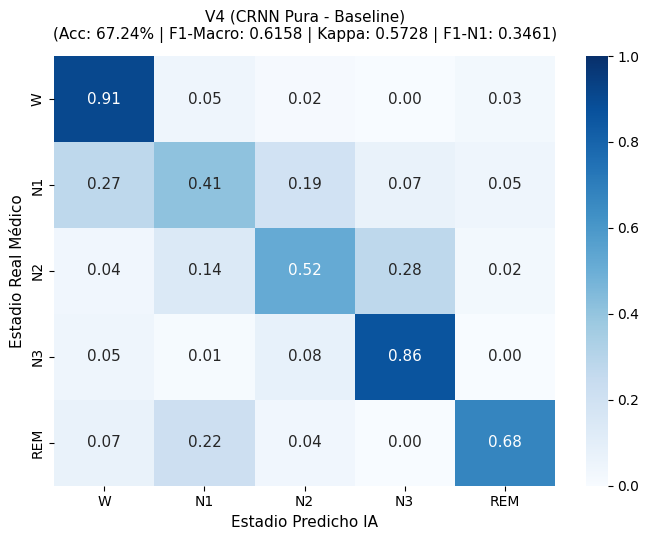

💾 Guardada: 01_matriz_v4_crnn_pura_baseline.png


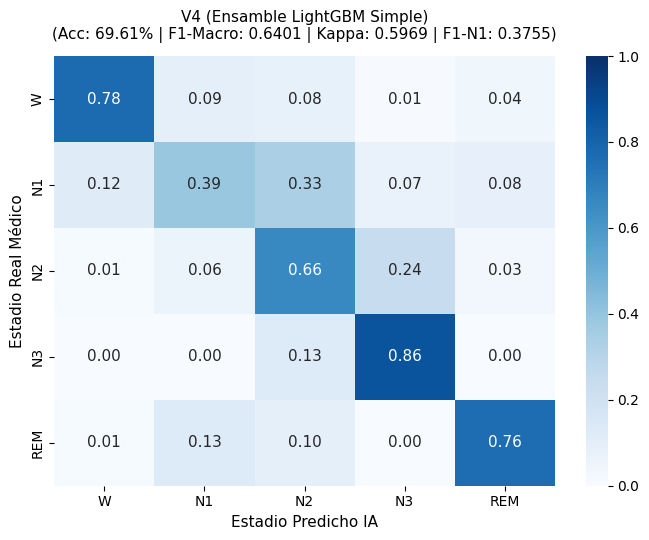

💾 Guardada: 02_matriz_v4_ensamble_lightgbm_simple.png


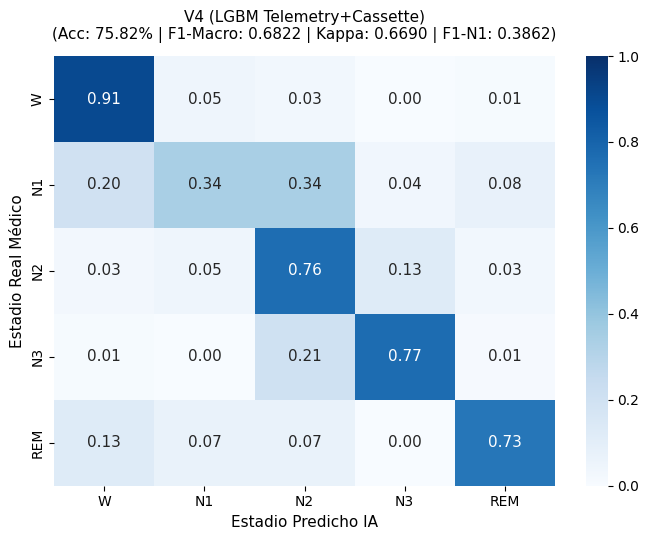

💾 Guardada: 03_matriz_v4_lgbm_telemetry_cassette.png


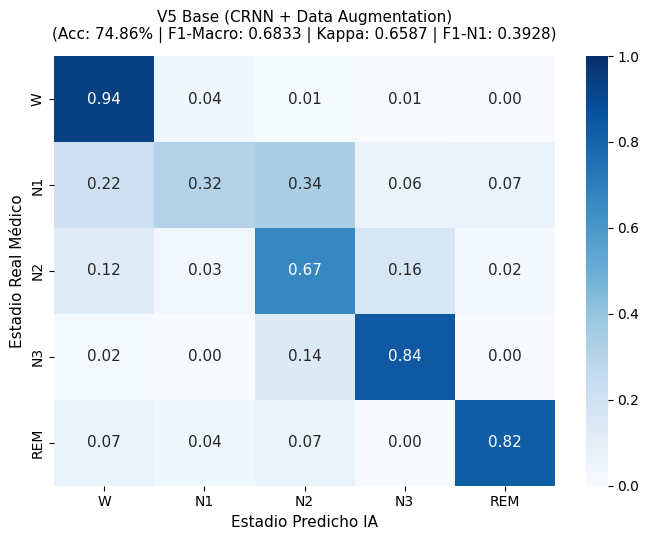

💾 Guardada: 04_matriz_v5_base_crnn_data_augmentation.png


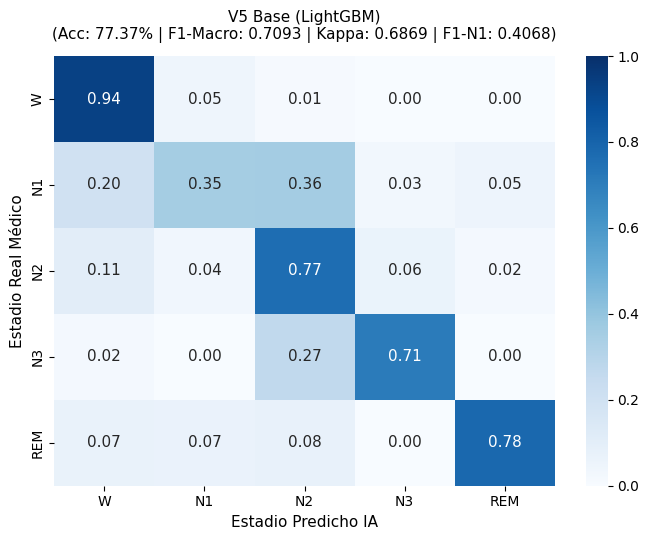

💾 Guardada: 05_matriz_v5_base_lightgbm.png


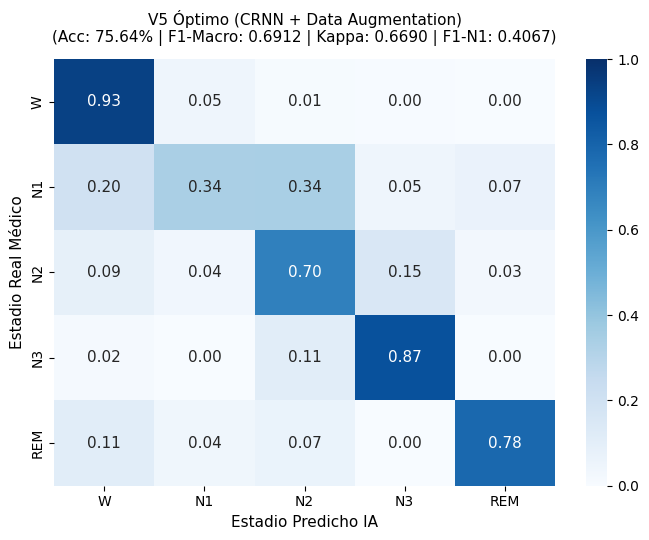

💾 Guardada: 06_matriz_v5_ptimo_crnn_data_augmentation.png


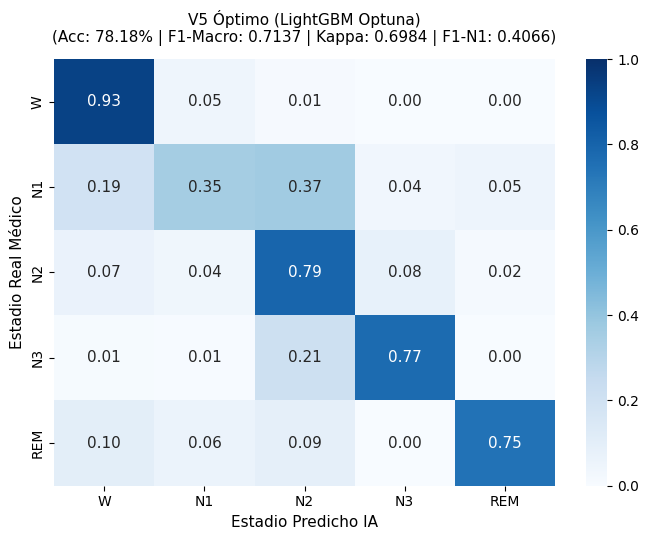

💾 Guardada: 07_matriz_v5_ptimo_lightgbm_optuna.png


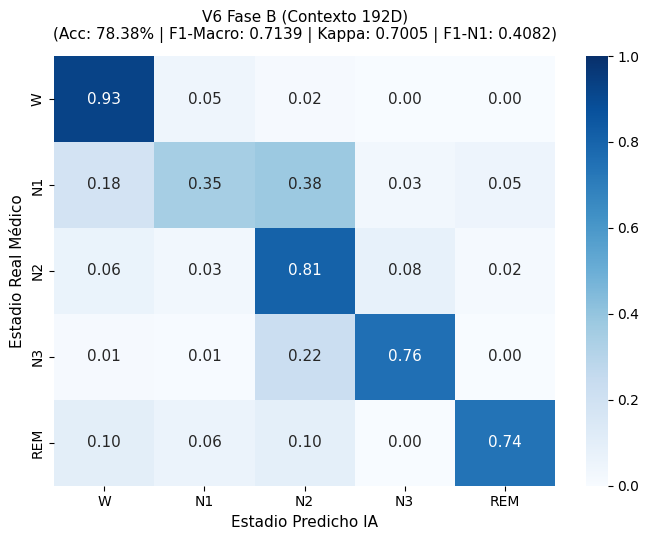

💾 Guardada: 08_matriz_v6_fase_b_contexto_192d.png


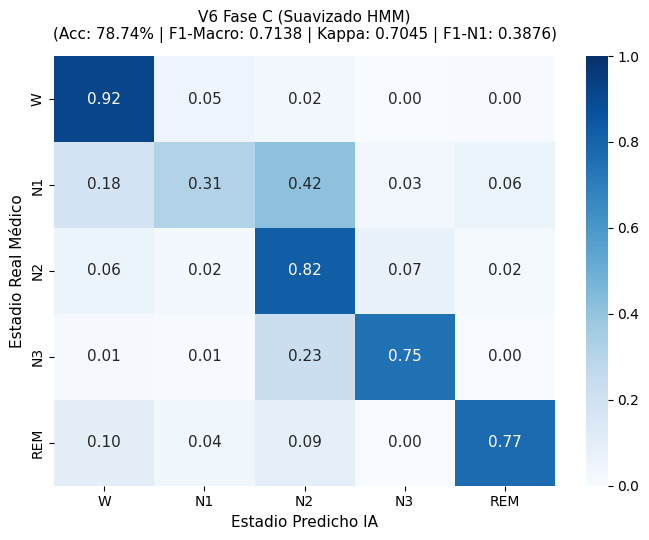

💾 Guardada: 09_matriz_v6_fase_c_suavizado_hmm.png


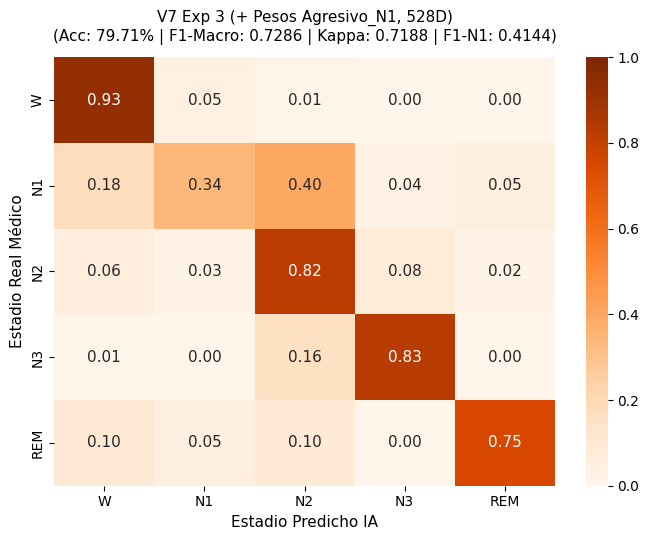

💾 Guardada: 10_matriz_v7_exp_3_pesos_agresivo_n1_528d.png


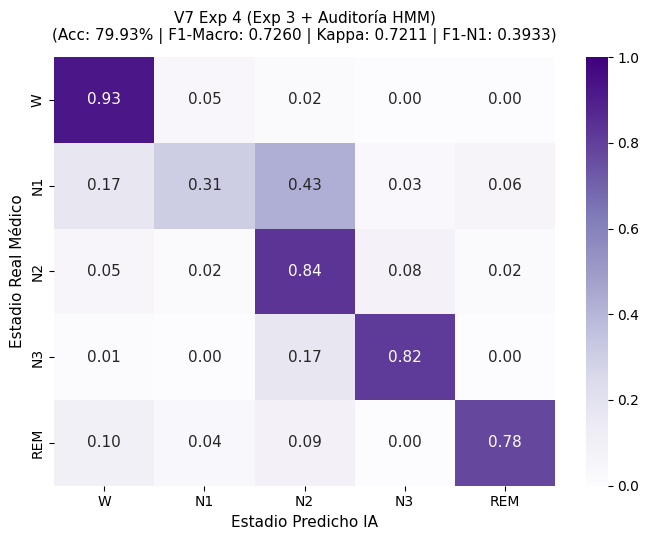

💾 Guardada: 11_matriz_v7_exp_4_exp_3_auditor_a_hmm.png

✅ Todas las matrices quedaron guardadas en:
   /content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry/tablas_paper_limpias/matrices_confusion


In [16]:
# ==============================================================================
# CELDA D: GENERAR Y GUARDAR MATRICES DE CONFUSIÓN EN IMÁGENES APARTE (300 DPI)
# ==============================================================================
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, cohen_kappa_score

CARPETA_MATRICES = BASE_TELEMETRY / "tablas_paper_limpias" / "matrices_confusion"
CARPETA_MATRICES.mkdir(parents=True, exist_ok=True)

# Respaldo automático por si ya corriste Celda B2 sin el diccionario en Celda A
if "predicciones_modelos" not in globals() or len(predicciones_modelos) == 0:
    predicciones_modelos = {}
    if "proba_v6" in globals():
        predicciones_modelos["V6 Fase B (Contexto 192D)"] = np.argmax(proba_v6, axis=1)
    if "y_v6_hmm" in globals():
        predicciones_modelos["V6 Fase C (Suavizado HMM)"] = y_v6_hmm
    if "y_pred_v7_exp3" in globals():
        predicciones_modelos["V7 Exp 3 (+ Pesos Agresivo_N1, 528D)"] = y_pred_v7_exp3
    if "y_pred_v7_exp4" in globals():
        predicciones_modelos["V7 Exp 4 (Exp 3 + Auditoría HMM)"] = y_pred_v7_exp4

print(f"📁 Carpeta de destino:\n   {CARPETA_MATRICES}\n")

for idx, (nombre, y_pred) in enumerate(predicciones_modelos.items(), 1):
    acc   = accuracy_score(y_true_holdout, y_pred)
    f1m   = f1_score(y_true_holdout, y_pred, average="macro")
    kap   = cohen_kappa_score(y_true_holdout, y_pred)
    f1_n1 = f1_score(y_true_holdout, y_pred, average=None, labels=[0, 1, 2, 3, 4])[1]

    cm = confusion_matrix(y_true_holdout, y_pred, normalize="true")

    # Color distinto para V7 final vs fases previas
    cmap = "Purples" if "Exp 4" in nombre else ("Oranges" if "Exp 3" in nombre else "Blues")

    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(
        cm, annot=True, fmt=".2f", cmap=cmap, ax=ax,
        xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS,
        vmin=0, vmax=1, annot_kws={"size": 11}
    )
    ax.set_title(
        f"{nombre}\n(Acc: {acc:.2%} | F1-Macro: {f1m:.4f} | Kappa: {kap:.4f} | F1-N1: {f1_n1:.4f})",
        fontsize=11, pad=12
    )
    ax.set_ylabel("Estadio Real Médico", fontsize=11)
    ax.set_xlabel("Estadio Predicho IA", fontsize=11)
    plt.tight_layout()

    # Nombre de archivo limpio
    slug = re.sub(r"[^a-zA-Z0-9]+", "_", nombre).strip("_").lower()
    ruta_img = CARPETA_MATRICES / f"{idx:02d}_matriz_{slug}.png"

    fig.savefig(ruta_img, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"💾 Guardada: {ruta_img.name}")

print(f"\n✅ Todas las matrices quedaron guardadas en:\n   {CARPETA_MATRICES}")

🚀 1/3 Evaluando V6 Fase D (TTA + HMM) sobre Hold-Out limpio...
✅ V6 Fase D (TTA + HMM)                      | Acc: 0.7891 | F1-M: 0.7145 | Kappa: 0.7065 | F1-N1: 0.3821

⏳ 2/3 Cargando Train (84 noches) y caché 192D para entrenar Exp 1 y Exp 2...
   Train procesado: 20/84 noches
   Train procesado: 40/84 noches
   Train procesado: 60/84 noches
   Train procesado: 80/84 noches
   Train procesado: 84/84 noches
🌲 Entrenando V7 Exp 1 (336D)...
✅ V7 Exp 1 (+ Bloques Espectrales 5s, 336D)  | Acc: 0.7927 | F1-M: 0.7235 | Kappa: 0.7127 | F1-N1: 0.4133
🌲 Entrenando V7 Exp 2 (528D)...
✅ V7 Exp 2 (+ Norm. Nocturna P10-P90, 528D)  | Acc: 0.7970 | F1-M: 0.7281 | Kappa: 0.7187 | F1-N1: 0.4120

📋 CUADRO III COMPLETO (HOLD-OUT LIMPIO):


,Modelo / Fase de Ablación,Accuracy,F1-Macro,Kappa
0,V4 (CRNN Pura - Baseline),0.6724,0.6158,0.5728
1,V4 (Ensamble LightGBM Simple),0.6961,0.6401,0.5969
2,V4 (LGBM Telemetry+Cassette),0.7582,0.6822,0.6690
3,V5 Base (CRNN + Data Augmentation),0.7486,0.6833,0.6587
4,V5 Base (LightGBM),0.7737,0.7093,0.6869
5,V5 Óptimo (CRNN + Data Augmentation),0.7564,0.6912,0.6690
6,V5 Óptimo (LightGBM Optuna),0.7818,0.7137,0.6984
7,V6 Fase B (Contexto 192D),0.7838,0.7139,0.7005
8,V6 Fase C (Suavizado HMM),0.7874,0.7138,0.7045
9,V6 Fase D (TTA + HMM),0.7891,0.7145,0.7065



📋 CUADRO IV COMPLETO (HOLD-OUT LIMPIO):


,Versión del Sistema,W,N1,N2,N3,REM
0,V4 (CRNN Pura - Baseline),0.87,0.35,0.64,0.48,0.74
1,V4 (Ensamble LightGBM Simple),0.85,0.38,0.70,0.51,0.77
2,V4 (LGBM Telemetry+Cassette),0.87,0.39,0.78,0.60,0.77
3,V5 Base (CRNN + Data Augmentation),0.86,0.39,0.73,0.58,0.85
4,V5 Base (LightGBM),0.86,0.41,0.78,0.66,0.83
5,V5 Óptimo (CRNN + Data Augmentation),0.86,0.41,0.75,0.61,0.82
6,V5 Óptimo (LightGBM Optuna),0.87,0.41,0.80,0.67,0.81
7,V6 Fase B (Contexto 192D),0.88,0.41,0.81,0.67,0.81
8,V6 Fase C (Suavizado HMM),0.87,0.39,0.81,0.67,0.83
9,V6 Fase D (TTA + HMM),0.87,0.38,0.81,0.68,0.83


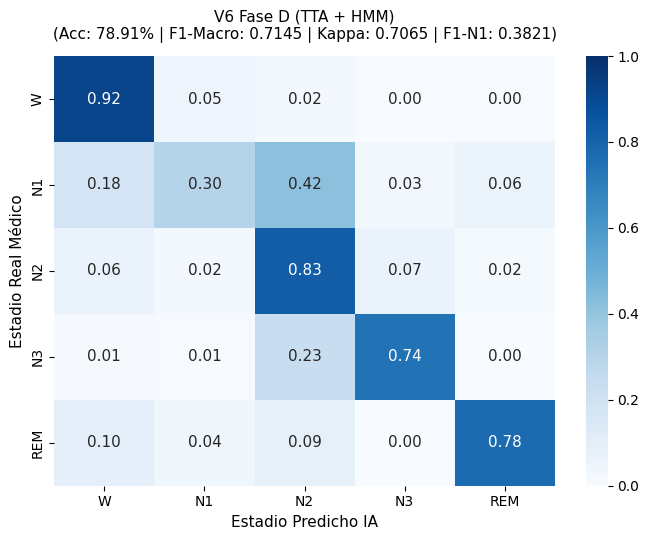

💾 Guardada: matriz_10_v6_fase_d_tta_hmm.png


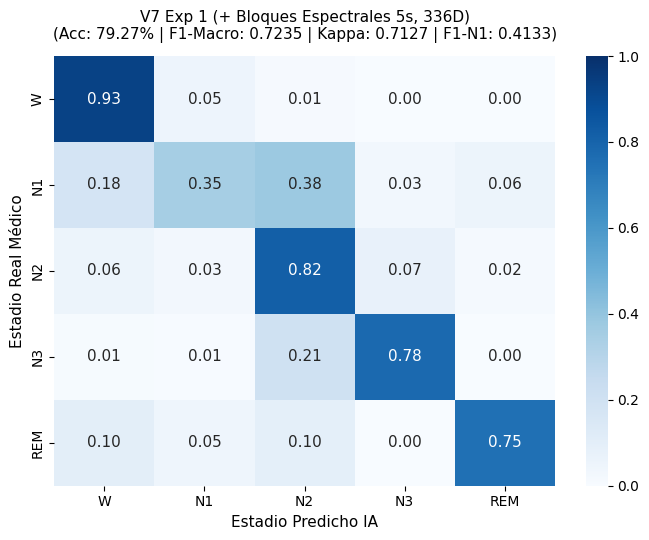

💾 Guardada: matriz_11_v7_exp_1_bloques_5s_336d.png


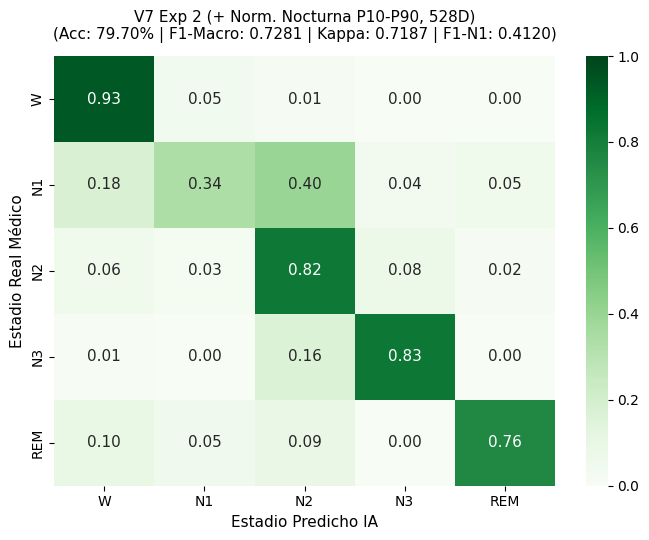

💾 Guardada: matriz_12_v7_exp_2_norm_nocturna_528d.png

✅ Tablas completas y 3 matrices nuevas guardadas en:
   /content/drive/MyDrive/Bimestre 7/Proyectos/sleep-telemetry/tablas_paper_limpias


In [17]:
# ==============================================================================
# CELDA E: COMPLETAR V6 FASE D (TTA+HMM), V7 EXP 1 Y V7 EXP 2 + TABLAS Y MATRICES
# ==============================================================================
import re
import gc
import time
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.fft import rfft
from scipy.ndimage import convolve1d
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, cohen_kappa_score

# ------------------------------------------------------------------------------
# 1. V6 FASE D (TTA 5 pasadas + Ensamble 192D + HMM)
# ------------------------------------------------------------------------------
print("🚀 1/3 Evaluando V6 Fase D (TTA + HMM) sobre Hold-Out limpio...")
crnn_v5o = load_model(BASE_TELEMETRY / "modelo_crnn_maestro_optimo_v7.keras",
                      custom_objects={"loss": categorical_focal_loss(gamma=1.5)})
ext_v5o = Model(inputs=crnn_v5o.inputs, outputs=crnn_v5o.layers[-2].output)
lgbm_v6 = joblib.load(BASE_TELEMETRY / "motor_lightgbm_contextual_192d_v7.pkl")

rng = np.random.default_rng(42)
emb_tta_acum = np.zeros((len(X_test_holdout), 64), dtype=np.float32)

for k in range(5):
    X_ruido = X_test_holdout + rng.normal(0.0, 0.05, size=X_test_holdout.shape).astype(np.float32)
    ds_tta = MultimodalDataGenerator(
        indices_test, X_ruido, y_test_holdout, reg_ids_test,
        seq_len=SEQ_LEN, batch_size=BATCH_SIZE, shuffle=False
    )
    emb_tta_acum += np.asarray(ext_v5o.predict(ds_tta, verbose=0), dtype=np.float32)
    del X_ruido, ds_tta

X_64d_tta  = emb_tta_acum / 5.0
X_192d_tta = expandir_contexto_192d(X_64d_tta, reg_ids_test)
proba_v6_tta = lgbm_v6.predict_proba(X_192d_tta)
y_pred_v6_d  = viterbi_con_pi(proba_v6_tta, reg_ids_test, A_hmm_v8, pi_hmm_v8)
registrar_resultado("V6 Fase D (TTA + HMM)", y_true_holdout, y_pred_v6_d)

del crnn_v5o, ext_v5o
tf.keras.backend.clear_session()
gc.collect()

# ------------------------------------------------------------------------------
# 2. V7 EXP 1 (336D) Y V7 EXP 2 (528D) — REUTILIZANDO CACHÉ 192D DE TRAIN
# ------------------------------------------------------------------------------
print("\n⏳ 2/3 Cargando Train (84 noches) y caché 192D para entrenar Exp 1 y Exp 2...")
RE_ST = re.compile(r"^ST7(\d{2})(\d)J0-PSG\.edf$", re.IGNORECASE)

def descubrir_registros_telemetry(base=BASE_TELEMETRY):
    registros = []
    for psg in sorted(Path(base).glob("*-PSG.edf")):
        m = RE_ST.match(psg.name)
        if not m: continue
        ss, noche = m.group(1), m.group(2)
        hyps = sorted(Path(base).glob(f"ST7{ss}{noche}J?-Hypnogram.edf"))
        if not hyps: continue
        registros.append({
            "psg": psg, "hyp": hyps[0], "registro_id": f"ST7{ss}{noche}",
            "sujeto_id": f"ST_S{ss}", "cohorte": "Telemetry", "noche": int(noche)
        })
    return registros

registros_train = descubrir_registros_telemetry(BASE_TELEMETRY) + registros_cas[:40]
Xs_tr, ys_tr, ms_tr = [], [], []
for idx_r, reg in enumerate(registros_train, 1):
    X_r, y_r, m_r = procesar_registro_cnn(reg)
    Xs_tr.append(X_r); ys_tr.append(np.argmax(y_r, axis=1)); ms_tr.append(m_r)
    if idx_r % 20 == 0 or idx_r == len(registros_train):
        print(f"   Train procesado: {idx_r}/{len(registros_train)} noches")

X_train_raw = np.concatenate(Xs_tr, axis=0)
y_train_num = np.concatenate(ys_tr, axis=0)
reg_train   = pd.concat(ms_tr, ignore_index=True)["registro_id"].to_numpy()
del Xs_tr, ys_tr, ms_tr; gc.collect()

# Cargar embeddings 192D de entrenamiento desde la caché
X_train_192d = np.load(BASE_TELEMETRY / "cache_embeddings_192d_v7.npz")["X_train_192d"]

# Extraer 336D espectrales de Train (los primeros 144 son Exp 1; los 336 completos son Exp 2)
X_train_336_spec = extraer_336d_por_noche(X_train_raw, reg_train)
del X_train_raw; gc.collect()

params_v7 = lgbm_v6.get_params()
params_v7.update({"n_jobs": -1, "verbose": -1, "random_state": 42})

# --- V7 Exp 1 (+ Bloques Espectrales 5s, 336D) ---
print("🌲 Entrenando V7 Exp 1 (336D)...")
X_train_exp1 = np.hstack((X_train_192d, X_train_336_spec[:, :144]))
X_ho_exp1    = np.hstack((X_192d_v6,    X_336d_spec[:, :144]))
clf_exp1 = lgb.LGBMClassifier(**params_v7)
clf_exp1.fit(X_train_exp1, y_train_num)
y_pred_v7_exp1 = clf_exp1.predict(X_ho_exp1)
registrar_resultado("V7 Exp 1 (+ Bloques Espectrales 5s, 336D)", y_true_holdout, y_pred_v7_exp1)
del X_train_exp1, clf_exp1; gc.collect()

# --- V7 Exp 2 (+ Norm. Nocturna P10-P90, 528D) ---
print("🌲 Entrenando V7 Exp 2 (528D)...")
X_train_exp2 = np.hstack((X_train_192d, X_train_336_spec))
clf_exp2 = lgb.LGBMClassifier(**params_v7)
clf_exp2.fit(X_train_exp2, y_train_num)
y_pred_v7_exp2 = clf_exp2.predict(X_528d_ho)
registrar_resultado("V7 Exp 2 (+ Norm. Nocturna P10-P90, 528D)", y_true_holdout, y_pred_v7_exp2)
del X_train_exp2, X_train_192d, X_train_336_spec, clf_exp2; gc.collect()

# ------------------------------------------------------------------------------
# 3. REORDENAR TABLAS COMPLETAS, GUARDAR CSV/LATEX Y GENERAR LAS 3 MATRICES NUEVAS
# ------------------------------------------------------------------------------
ORDEN_FINAL = [
    "V4 (CRNN Pura - Baseline)",
    "V4 (Ensamble LightGBM Simple)",
    "V4 (LGBM Telemetry+Cassette)",
    "V5 Base (CRNN + Data Augmentation)",
    "V5 Base (LightGBM)",
    "V5 Óptimo (CRNN + Data Augmentation)",
    "V5 Óptimo (LightGBM Optuna)",
    "V6 Fase B (Contexto 192D)",
    "V6 Fase C (Suavizado HMM)",
    "V6 Fase D (TTA + HMM)",
    "V7 Exp 1 (+ Bloques Espectrales 5s, 336D)",
    "V7 Exp 2 (+ Norm. Nocturna P10-P90, 528D)",
    "V7 Exp 3 (+ Pesos Agresivo_N1, 528D)",
    "V7 Exp 4 (Exp 3 + Auditoría HMM)",
]

df_c3 = pd.DataFrame(resultados_global).drop_duplicates(subset=["Modelo / Fase de Ablación"], keep="last")
df_c3["orden"] = df_c3["Modelo / Fase de Ablación"].apply(lambda x: ORDEN_FINAL.index(x) if x in ORDEN_FINAL else 99)
df_c3 = df_c3.sort_values("orden").drop(columns=["orden"]).reset_index(drop=True)

df_c4 = pd.DataFrame(resultados_estadios).drop_duplicates(subset=["Versión del Sistema"], keep="last")
df_c4["orden"] = df_c4["Versión del Sistema"].apply(lambda x: ORDEN_FINAL.index(x) if x in ORDEN_FINAL else 99)
df_c4 = df_c4.sort_values("orden").drop(columns=["orden"]).reset_index(drop=True)

CARPETA_SALIDA = BASE_TELEMETRY / "tablas_paper_limpias"
CARPETA_MATRICES = CARPETA_SALIDA / "matrices_confusion"
CARPETA_MATRICES.mkdir(parents=True, exist_ok=True)

df_c3.to_csv(CARPETA_SALIDA / "cuadro3_global_limpio.csv", index=False)
df_c4.to_csv(CARPETA_SALIDA / "cuadro4_estadios_limpio.csv", index=False)
df_c3.to_latex(CARPETA_SALIDA / "cuadro3_global_limpio.tex", index=False, float_format="%.4f")
df_c4.to_latex(CARPETA_SALIDA / "cuadro4_estadios_limpio.tex", index=False, float_format="%.2f")

print("\n📋 CUADRO III COMPLETO (HOLD-OUT LIMPIO):")
display(df_c3)
print("\n📋 CUADRO IV COMPLETO (HOLD-OUT LIMPIO):")
display(df_c4)

# Guardar las 3 matrices nuevas
nuevos_modelos = [
    ("10_v6_fase_d_tta_hmm", "V6 Fase D (TTA + HMM)", y_pred_v6_d, "Blues"),
    ("11_v7_exp_1_bloques_5s_336d", "V7 Exp 1 (+ Bloques Espectrales 5s, 336D)", y_pred_v7_exp1, "Blues"),
    ("12_v7_exp_2_norm_nocturna_528d", "V7 Exp 2 (+ Norm. Nocturna P10-P90, 528D)", y_pred_v7_exp2, "Greens"),
]

for fname, titulo, y_p, cmap in nuevos_modelos:
    acc   = accuracy_score(y_true_holdout, y_p)
    f1m   = f1_score(y_true_holdout, y_p, average="macro")
    kap   = cohen_kappa_score(y_true_holdout, y_p)
    f1_n1 = f1_score(y_true_holdout, y_p, average=None, labels=[0, 1, 2, 3, 4])[1]
    cm    = confusion_matrix(y_true_holdout, y_p, normalize="true")

    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap, ax=ax,
                xticklabels=ETAPAS_VALIDAS, yticklabels=ETAPAS_VALIDAS, vmin=0, vmax=1, annot_kws={"size": 11})
    ax.set_title(f"{titulo}\n(Acc: {acc:.2%} | F1-Macro: {f1m:.4f} | Kappa: {kap:.4f} | F1-N1: {f1_n1:.4f})", fontsize=11, pad=12)
    ax.set_ylabel("Estadio Real Médico", fontsize=11)
    ax.set_xlabel("Estadio Predicho IA", fontsize=11)
    plt.tight_layout()

    ruta_img = CARPETA_MATRICES / f"matriz_{fname}.png"
    fig.savefig(ruta_img, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"💾 Guardada: {ruta_img.name}")

print(f"\n✅ Tablas completas y 3 matrices nuevas guardadas en:\n   {CARPETA_SALIDA}")